# Significance testing and canonical table/figure regeneration: HEALPix vs. native UTM

This notebook is the single reproducible source of truth for Tables III-VI and
Figure 1 of the paper, replacing the ad-hoc, unsaved analysis scripts used to
generate the first draft of those tables. It reads the two already-computed
sweep result files (`results/hpx_codec_bench.csv`, `results/utm_codec_bench.csv`,
written by `hpx_codec_bench.ipynb` and `utm_codec_bench.ipynb`) and does not
re-run any compression itself.

**Why this notebook exists.** The first published draft of Tables IV-VI and
Figure 1 applied the operational tiling overhead $\gamma_{\mathrm{UTM}}=1.30$
inconsistently: Table III (uncompressed storage) applied it correctly, but the
post-compression tables/figure omitted it on the UTM side entirely. A second,
intermediate fix applied it by inflating the UTM *raw-size denominator*
(`compressed / (raw*1.3)`), which is mathematically wrong for the opposite
reason: it implicitly assumes the padded/overlapping ~30% of a real UTM tile
compresses to *zero* extra bytes.

The methodology below applies $\gamma_{\mathrm{UTM}}$ the physically correct
way: **directly to the UTM side's compressed byte count**, on the grounds that
a real operational product would also have to compress its padding/overlap,
and that compression is applied *after* accounting for the two grids' very
different pixel counts for the same real-world footprint (HEALPix level-20
carrier tile: $1024\times1024$ cells; footprint-matched native UTM crop:
roughly $637\times637$ pixels). The two are therefore compared directly in
**compressed bytes for the same footprint**, using the fixed HEALPix raw tile
size ($\num{4194304}$ bytes) as a single shared reference for both sides.

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
from scipy import stats
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

RESULTS_DIR = Path("results")
FIGURES_DIR = Path("../tex/figures")
TABLES_DIR = Path("../tex/tables")
GAMMA_UTM = 1.30
SHARED_RAW = 4_194_304  # fixed HEALPix level-20 tile raw size (bytes), constant across scenes
SCENES = ["urban", "water", "forest", "agriculture", "snow_ice", "clouds", "ocean"]
TARGET_RMSE = [1e-4, 3e-4, 1e-3, 3e-3, 1e-2]
BUDGETS = [0.40, 0.20, 0.10, 0.05, 0.02]
MIN_SCENES = 3  # minimum scene coverage for a codec to be "evaluable" at a target

hpx = pd.read_csv(RESULTS_DIR / "hpx_codec_bench.csv")
utm = pd.read_csv(RESULTS_DIR / "utm_codec_bench.csv")
COMPRESSOR_CODECS = [c for c in hpx.codec.unique() if c != "uncompressed"]
CODEC_LABEL = {
    "zfp": "ZFP", "sz3": "SZ3", "jpeg2000_lossy": "JPEG~2000",
    "jpegxl_lossy": "JPEG~XL", "dwt_zstd": "DWT+zstd",
    "jpeg2000_lossless": "JPEG~2000 (lossless)", "jpegxl_lossless": "JPEG~XL (lossless)",
}
print(f"HPX rows: {len(hpx)}, UTM rows: {len(utm)}, codecs: {COMPRESSOR_CODECS}")

HPX rows: 322, UTM rows: 322, codecs: ['zfp', 'sz3', 'jpeg2000_lossy', 'jpeg2000_lossless', 'jpegxl_lossy', 'jpegxl_lossless', 'dwt_zstd']


In [2]:
def _xy(df, xcol, ycol):
    """Sort + average duplicate x values; NOT a Pareto frontier -- interpolates
    the raw sweep points directly (Section IV-B of the paper)."""
    d = df[[xcol, ycol]].replace([np.inf, -np.inf], np.nan).dropna()
    d = d[(d[xcol] > 0) & (d[ycol] > 0)]
    if len(d) < 2:
        return None
    d = d.groupby(xcol, as_index=False)[ycol].mean().sort_values(xcol)
    return d[xcol].to_numpy(), d[ycol].to_numpy()

def interp_size_at_rmse(df, target):
    xy = _xy(df, "rmse", "total_bytes")
    if xy is None: return np.nan
    x, y = xy
    if not (x.min() <= target <= x.max()): return np.nan
    return float(np.exp(np.interp(np.log(target), np.log(x), np.log(y))))

def interp_rmse_at_size(df, target):
    xy = _xy(df, "total_bytes", "rmse")
    if xy is None: return np.nan
    x, y = xy
    if not (x.min() <= target <= x.max()): return np.nan
    return float(np.exp(np.interp(np.log(target), np.log(x), np.log(y))))

## Table IV: storage at constant RMSE (shared reference, UTM x1.30 on compressed bytes)

In [3]:
rows_iv = []
for target in TARGET_RMSE:
    hpx_medians, utm_medians = {}, {}
    for cd in COMPRESSOR_CODECS:
        h = [interp_size_at_rmse(hpx[(hpx.scene == s) & (hpx.codec == cd)], target) for s in SCENES]
        h = [v for v in h if np.isfinite(v)]
        if len(h) >= MIN_SCENES:
            hpx_medians[cd] = np.median(h) / SHARED_RAW * 100
        u = [interp_size_at_rmse(utm[(utm.scene == s) & (utm.codec == cd)], target) for s in SCENES]
        u = [v * GAMMA_UTM for v in u if np.isfinite(v)]
        if len(u) >= MIN_SCENES:
            utm_medians[cd] = np.median(u) / SHARED_RAW * 100
    bh = min(hpx_medians, key=hpx_medians.get)
    bu = min(utm_medians, key=utm_medians.get)
    rows_iv.append((target, hpx_medians[bh], utm_medians[bu], bh, bu, len(hpx_medians), len(utm_medians)))
    print(f"target={target:.0e}  HPX={hpx_medians[bh]:6.2f}% ({bh:14s})  "
          f"UTM_op={utm_medians[bu]:6.2f}% ({bu:14s})")
table_iv_df = pd.DataFrame(rows_iv, columns=["target_rmse", "hpx_pct", "utm_pct", "best_hpx", "best_utm", "n_hpx", "n_utm"])
table_iv_df

target=1e-04  HPX= 17.28% (sz3           )  UTM_op= 18.82% (jpeg2000_lossy)


target=3e-04  HPX= 12.42% (sz3           )  UTM_op= 13.67% (jpeg2000_lossy)


target=1e-03  HPX=  7.10% (sz3           )  UTM_op=  8.67% (jpegxl_lossy  )


target=3e-03  HPX=  4.60% (sz3           )  UTM_op=  4.12% (jpeg2000_lossy)


target=1e-02  HPX=  1.38% (dwt_zstd      )  UTM_op=  0.77% (jpeg2000_lossy)


,target_rmse,hpx_pct,utm_pct,best_hpx,best_utm,n_hpx,n_utm
0,0.0001,17.275377,18.823048,sz3,jpeg2000_lossy,4,4
1,0.0003,12.416124,13.667271,sz3,jpeg2000_lossy,4,4
2,0.0010,7.100686,8.669660,sz3,jpegxl_lossy,5,5
3,0.0030,4.597349,4.121056,sz3,jpeg2000_lossy,5,5
4,0.0100,1.380985,0.766161,dwt_zstd,jpeg2000_lossy,4,4


## Table V: RMSE at constant shared budget (UTM target deflated by /1.30 before interpolation)

In [4]:
rows_v = []
for frac in BUDGETS:
    budget_bytes = frac * SHARED_RAW
    hpx_medians, utm_medians = {}, {}
    for cd in COMPRESSOR_CODECS:
        h = [interp_rmse_at_size(hpx[(hpx.scene == s) & (hpx.codec == cd)], budget_bytes) for s in SCENES]
        h = [v for v in h if np.isfinite(v)]
        if len(h) >= MIN_SCENES:
            hpx_medians[cd] = np.median(h)
        u = [interp_rmse_at_size(utm[(utm.scene == s) & (utm.codec == cd)], budget_bytes / GAMMA_UTM) for s in SCENES]
        u = [v for v in u if np.isfinite(v)]
        if len(u) >= MIN_SCENES:
            utm_medians[cd] = np.median(u)
    bh = min(hpx_medians, key=hpx_medians.get) if hpx_medians else None
    bu = min(utm_medians, key=utm_medians.get) if utm_medians else None
    hv = hpx_medians[bh] if bh else np.nan
    uv = utm_medians[bu] if bu else np.nan
    rows_v.append((frac, hv, uv, bh, bu))
    print(f"budget={frac:5.0%}  HPX_RMSE={hv:.3e} ({bh})  UTM_RMSE={uv:.3e} ({bu})")
table_v_df = pd.DataFrame(rows_v, columns=["budget", "hpx_rmse", "utm_rmse", "best_hpx", "best_utm"])
table_v_df

budget=  40%  HPX_RMSE=4.396e-06 (zfp)  UTM_RMSE=4.631e-06 (zfp)


budget=  20%  HPX_RMSE=5.607e-05 (sz3)  UTM_RMSE=7.706e-05 (jpeg2000_lossy)


budget=  10%  HPX_RMSE=4.782e-04 (sz3)  UTM_RMSE=6.445e-04 (sz3)


budget=   5%  HPX_RMSE=1.621e-03 (sz3)  UTM_RMSE=1.873e-03 (jpegxl_lossy)


budget=   2%  HPX_RMSE=4.965e-03 (sz3)  UTM_RMSE=3.786e-03 (jpeg2000_lossy)


,budget,hpx_rmse,utm_rmse,best_hpx,best_utm
0,0.40,0.000004,0.000005,zfp,zfp
1,0.20,0.000056,0.000077,sz3,jpeg2000_lossy
2,0.10,0.000478,0.000645,sz3,sz3
3,0.05,0.001621,0.001873,sz3,jpegxl_lossy
4,0.02,0.004965,0.003786,sz3,jpeg2000_lossy


## Paired significance tests

For each target RMSE / budget with sufficient scene coverage, compute the
per-scene best-achievable value (oracle codec selection per scene, an
idealized upper bound distinct from Tables IV-V's single-fixed-codec
convention), then run a paired Wilcoxon signed-rank test across the seven
scenes, plus an aggregate sign test across all evaluable targets.

In [5]:
def best_of_codecs_size(df_side, scene, codec_list, target, gamma=1.0):
    vals = [interp_size_at_rmse(df_side[(df_side.scene == scene) & (df_side.codec == cd)], target) for cd in codec_list]
    vals = [v * gamma for v in vals if np.isfinite(v)]
    return min(vals) if vals else np.inf

def best_of_codecs_rmse(df_side, scene, codec_list, target_bytes):
    vals = [interp_rmse_at_size(df_side[(df_side.scene == scene) & (df_side.codec == cd)], target_bytes) for cd in codec_list]
    vals = [v for v in vals if np.isfinite(v)]
    return min(vals) if vals else np.inf

sig_rows = []
for target in TARGET_RMSE:
    hf = [best_of_codecs_size(hpx, s, COMPRESSOR_CODECS, target) for s in SCENES]
    uf = [best_of_codecs_size(utm, s, COMPRESSOR_CODECS, target, gamma=GAMMA_UTM) for s in SCENES]
    pairs = [(h, u) for h, u in zip(hf, uf) if np.isfinite(h) and np.isfinite(u)]
    n = len(pairs)
    if n >= 2:
        h_arr = np.array([p[0] for p in pairs]); u_arr = np.array([p[1] for p in pairs])
        w = stats.wilcoxon(h_arr - u_arr, alternative="two-sided",
                            method="exact" if n <= 25 else "auto")
        med_ratio = float(np.median(h_arr / u_arr))
        sig_rows.append(dict(kind="rmse_target", target=target, n=n,
                              median_hpx_over_utm=med_ratio, wilcoxon_p=w.pvalue,
                              favors="HPX" if med_ratio < 1 else "UTM"))

for frac in BUDGETS:
    budget_bytes = frac * SHARED_RAW
    hf = [best_of_codecs_rmse(hpx, s, COMPRESSOR_CODECS, budget_bytes) for s in SCENES]
    uf = [best_of_codecs_rmse(utm, s, COMPRESSOR_CODECS, budget_bytes / GAMMA_UTM) for s in SCENES]
    pairs = [(h, u) for h, u in zip(hf, uf) if np.isfinite(h) and np.isfinite(u)]
    n = len(pairs)
    if n >= 2:
        h_arr = np.array([p[0] for p in pairs]); u_arr = np.array([p[1] for p in pairs])
        w = stats.wilcoxon(h_arr - u_arr, alternative="two-sided",
                            method="exact" if n <= 25 else "auto")
        med_ratio = float(np.median(h_arr / u_arr))
        sig_rows.append(dict(kind="budget", target=frac, n=n,
                              median_hpx_over_utm=med_ratio, wilcoxon_p=w.pvalue,
                              favors="HPX" if med_ratio < 1 else "UTM"))

sig_df = pd.DataFrame(sig_rows)
print(sig_df.to_string(index=False))

n_hpx = (sig_df.favors == "HPX").sum()
n_total = len(sig_df)
sign_p = stats.binomtest(n_hpx, n_total, 0.5).pvalue
print(f"\nHPX favored in {n_hpx}/{n_total} evaluable targets; two-sided sign-test p = {sign_p:.4f}")
sig_df.to_csv(RESULTS_DIR / "significance_tests.csv", index=False)

       kind  target  n  median_hpx_over_utm  wilcoxon_p favors
rmse_target  0.0001  7             0.934519    0.031250    HPX
rmse_target  0.0003  7             0.921036    0.078125    HPX
rmse_target  0.0010  7             0.932408    0.218750    HPX
rmse_target  0.0030  5             0.966454    1.000000    HPX
rmse_target  0.0100  5             1.394983    0.437500    UTM
     budget  0.4000  6             0.725197    0.312500    HPX
     budget  0.2000  7             0.798493    0.078125    HPX
     budget  0.1000  7             0.754120    0.218750    HPX
     budget  0.0500  7             0.937822    0.687500    HPX
     budget  0.0200  7             1.047629    0.687500    UTM

HPX favored in 8/10 evaluable targets; two-sided sign-test p = 0.1094


## Bootstrap confidence interval on the raw-storage ratio (Table III)

Percentile bootstrap (10,000 resamples of the 7 scenes) on the mean
HPX-raw / UTM-operational ratio, complementing the exact Wilcoxon test.

In [6]:
raw_utm_cropped = utm[utm.codec == "uncompressed"].set_index("scene")["total_bytes"].to_dict()
ratio = np.array([SHARED_RAW / (raw_utm_cropped[s] * GAMMA_UTM) for s in SCENES])
print("per-scene ratio:", dict(zip(SCENES, ratio.round(4))))
print("mean:", ratio.mean(), " median:", np.median(ratio))

w = stats.wilcoxon(ratio - 1.0, alternative="two-sided", method="exact")
print("Wilcoxon (diff from 1.0):", w)

rng = np.random.default_rng(0)
boot = [np.mean(rng.choice(ratio, size=len(ratio), replace=True)) for _ in range(10_000)]
ci = np.percentile(boot, [2.5, 97.5])
print(f"bootstrap 95% CI on mean ratio: [{ci[0]:.4f}, {ci[1]:.4f}]")

per-scene ratio: {'urban': np.float64(0.9779), 'water': np.float64(0.9346), 'forest': np.float64(0.9705), 'agriculture': np.float64(0.9522), 'snow_ice': np.float64(0.9932), 'clouds': np.float64(0.9192), 'ocean': np.float64(0.9308)}
mean: 0.9540574970414382  median: 0.9521816956087129
Wilcoxon (diff from 1.0): WilcoxonResult(statistic=np.float64(0.0), pvalue=np.float64(0.015625))
bootstrap 95% CI on mean ratio: [0.9356, 0.9729]


## Regenerate Figure 1 (storage/error curves, corrected methodology)

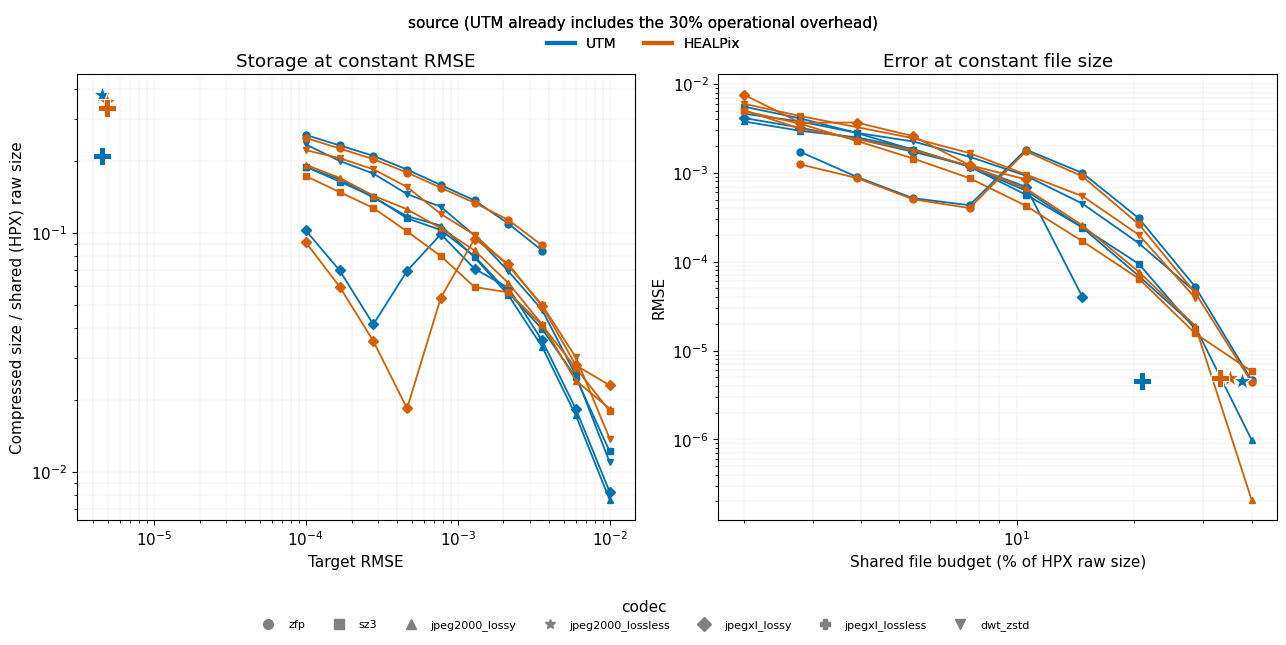

In [7]:
hpx2 = hpx.copy(); hpx2["source"] = "HEALPix"
utm2 = utm.copy(); utm2["source"] = "UTM"
combined = pd.concat([hpx2, utm2], ignore_index=True)
LOSSLESS_CODECS = {"jpeg2000_lossless", "jpegxl_lossless"}
SOURCE_COLOR = {"UTM": "#0072B2", "HEALPix": "#D55E00"}
CODEC_STYLE = {
    "zfp": dict(color="#0072B2", marker="o"), "sz3": dict(color="#D55E00", marker="s"),
    "jpeg2000_lossy": dict(color="#009E73", marker="^"), "jpeg2000_lossless": dict(color="#000000", marker="*"),
    "jpegxl_lossy": dict(color="#CC79A7", marker="D"), "jpegxl_lossless": dict(color="#E69F00", marker="P"),
    "dwt_zstd": dict(color="#56B4E9", marker="v"),
}
TARGET_RMSE_VALUES = np.geomspace(1e-4, 1e-2, 10)
FILE_BUDGET_FRACTIONS = np.geomspace(0.02, 0.40, 10)

plt.rcParams["figure.figsize"] = (8, 5.5)
plt.rcParams["font.size"] = 11
fig, (axL, axR) = plt.subplots(1, 2, figsize=(13, 5.5))

for source in ("UTM", "HEALPix"):
    src_df = combined[combined.source == source]
    color = SOURCE_COLOR[source]
    gamma = GAMMA_UTM if source == "UTM" else 1.0
    for codec in COMPRESSOR_CODECS:
        cd_df = src_df[src_df.codec == codec]
        if cd_df.empty: continue
        marker = CODEC_STYLE.get(codec, dict(marker="x"))["marker"]
        scenes = cd_df.scene.unique()
        if codec in LOSSLESS_CODECS:
            fracs = [cd_df[cd_df.scene == s].total_bytes.iloc[0] * gamma / SHARED_RAW for s in scenes]
            rmses = [cd_df[cd_df.scene == s].rmse.iloc[0] for s in scenes]
            if fracs:
                axL.scatter(np.median(rmses), np.median(fracs), color=color, marker=marker, s=180, edgecolor="white", linewidth=0.7, zorder=5)
                axR.scatter(np.median(fracs) * 100, np.median(rmses), color=color, marker=marker, s=180, edgecolor="white", linewidth=0.7, zorder=5)
            continue
        left_y = []
        for target in TARGET_RMSE_VALUES:
            fracs = [interp_size_at_rmse(cd_df[cd_df.scene == s], target) * gamma / SHARED_RAW for s in scenes]
            fracs = [f for f in fracs if np.isfinite(f)]
            left_y.append(np.median(fracs) if fracs else np.nan)
        left_y = np.array(left_y); valid = np.isfinite(left_y)
        if valid.sum() >= 2:
            axL.plot(TARGET_RMSE_VALUES[valid], left_y[valid], color=color, marker=marker, markersize=5, linewidth=1.3)
        right_y = []
        for frac in FILE_BUDGET_FRACTIONS:
            target_bytes = frac * SHARED_RAW / gamma
            rmses = [interp_rmse_at_size(cd_df[cd_df.scene == s], target_bytes) for s in scenes]
            rmses = [r for r in rmses if np.isfinite(r)]
            right_y.append(np.median(rmses) if rmses else np.nan)
        right_y = np.array(right_y); valid = np.isfinite(right_y)
        if valid.sum() >= 2:
            axR.plot(FILE_BUDGET_FRACTIONS[valid] * 100, right_y[valid], color=color, marker=marker, markersize=5, linewidth=1.3)

axL.set_xscale("log"); axL.set_yscale("log")
axL.set_xlabel("Target RMSE"); axL.set_ylabel("Compressed size / shared (HPX) raw size")
axL.set_title("Storage at constant RMSE"); axL.grid(True, which="both", linewidth=0.3, alpha=0.4)
axR.set_xscale("log"); axR.set_yscale("log")
axR.set_xlabel("Shared file budget (% of HPX raw size)"); axR.set_ylabel("RMSE")
axR.set_title("Error at constant file size"); axR.grid(True, which="both", linewidth=0.3, alpha=0.4)

source_handles = [Line2D([0], [0], color=SOURCE_COLOR[s], lw=3, label=s) for s in ("UTM", "HEALPix")]
codec_handles = [Line2D([0], [0], color="grey", marker=CODEC_STYLE.get(c, dict(marker="x"))["marker"], linestyle="", markersize=7, label=c) for c in COMPRESSOR_CODECS]
leg1 = fig.legend(handles=source_handles, loc="upper center", bbox_to_anchor=(0.5, 1.06), ncol=2, fontsize=10, frameon=False,
                   title="source (UTM already includes the 30% operational overhead)")
fig.add_artist(leg1)
fig.legend(handles=codec_handles, loc="lower center", bbox_to_anchor=(0.5, -0.1), ncol=7, fontsize=8, frameon=False, title="codec")
fig.tight_layout()
FIGURES_DIR.mkdir(exist_ok=True, parents=True)
fig.savefig(FIGURES_DIR / "fig_storage_at_constant_rmse.pdf", bbox_inches="tight")
fig.savefig(FIGURES_DIR / "fig_storage_at_constant_rmse.png", dpi=150, bbox_inches="tight")
fig.savefig(FIGURES_DIR / "fig_error_at_constant_size.pdf", bbox_inches="tight")
fig.savefig(FIGURES_DIR / "fig_error_at_constant_size.png", dpi=150, bbox_inches="tight")
plt.show()

## Write LaTeX table files

Regenerates `tex/tables/table_storage_at_constant_rmse.tex` and
`tex/tables/table_error_at_constant_size.tex` directly from `table_iv_df` /
`table_v_df` above, so the paper's numbers can never drift from this
notebook's computation again.

In [8]:
def fmt_rmse(x):
    if not np.isfinite(x): return "--"
    exp = int(np.floor(np.log10(x))); mant = x / 10**exp
    return f"${round(mant,2)}\\times10^{{{exp}}}$"

tex_iv = [r"\begin{table}[t]", r"\centering",
    r"\caption{Storage at constant reconstruction RMSE, best codec at each target, median across the seven scenes. Both columns are expressed as a percentage of the same shared reference, the fixed $1024\times1024$ level-20 HEALPix raw tile size, so the two columns are directly comparable in bytes. \emph{UTM}: compressed bytes on the footprint-exact crop, scaled by the operational tiling factor $\gamma_{\mathrm{UTM}}=1.30$ (Section~\ref{sec:overhead}). $^\dagger$: fewer than 6 of the 7 scenes have an evaluable point for any codec at this target.}",
    r"\label{tab:storage_at_rmse}", r"\begin{tabular}{lrrll}", r"\toprule",
    r"Target RMSE & HPX (\% shared) & UTM op.\ (\% shared) & Best HPX codec & Best UTM codec \\", r"\midrule"]
tstr_map = {1e-4: "$10^{-4}$", 3e-4: "$3\\times10^{-4}$", 1e-3: "$10^{-3}$", 3e-3: "$3\\times10^{-3}$", 1e-2: "$10^{-2}$$^\\dagger$"}
for _, r in table_iv_df.iterrows():
    tex_iv.append(f"{tstr_map[r.target_rmse]} & {r.hpx_pct:.2f} & {r.utm_pct:.2f} & {CODEC_LABEL.get(r.best_hpx, r.best_hpx)} & {CODEC_LABEL.get(r.best_utm, r.best_utm)} \\\\")
tex_iv += [r"\bottomrule", r"\end{tabular}", r"\end{table}"]
(TABLES_DIR / "table_storage_at_constant_rmse.tex").write_text("\n".join(tex_iv) + "\n")

tex_v = [r"\begin{table}[t]", r"\centering",
    r"\caption{Reconstruction RMSE at a constant, shared storage budget (percentage of the fixed HEALPix raw tile size, applied identically to both grids). \emph{UTM}: the byte budget available for the footprint-exact crop's own compression is the shared budget divided by $\gamma_{\mathrm{UTM}}=1.30$. Best codec at each budget, median across scenes.}",
    r"\label{tab:error_at_size}", r"\begin{tabular}{lrrll}", r"\toprule",
    r"Budget (\% shared) & HPX RMSE & UTM RMSE & Best HPX codec & Best UTM codec \\", r"\midrule"]
for _, r in table_v_df.iterrows():
    hcs = CODEC_LABEL.get(r.best_hpx, r.best_hpx) if r.best_hpx else "--"
    ucs = CODEC_LABEL.get(r.best_utm, r.best_utm) if r.best_utm else "--"
    tex_v.append(f"{r.budget:.0%}".replace("%", "\\%") + f" & {fmt_rmse(r.hpx_rmse)} & {fmt_rmse(r.utm_rmse)} & {hcs} & {ucs} \\\\")
tex_v += [r"\bottomrule", r"\end{tabular}", r"\end{table}"]
(TABLES_DIR / "table_error_at_constant_size.tex").write_text("\n".join(tex_v) + "\n")
print("LaTeX tables written to", TABLES_DIR)

LaTeX tables written to ../tex/tables
